# 2. Measure raster objects

Calculate spectral distributions, a band-ratio feature, shape, and texture.
Inspect an analysis mask and save the features with their settings.

This notebook runs independently with the small Chesapeake sample included in
OBIA. No data download is needed. From a repository checkout, install
`python -m pip install -e ".[notebooks]"`, then launch `jupyter lab`.
See the [sample data and setup guide](https://obia.sefa.ai/examples/) for
provenance, class codes, and source terms.

Run the cells from top to bottom. Files go into this notebook's subdirectory of
`example_outputs/`; rerunning replaces those example files. All OBIA band selections
use **zero-based numeric indices** into the loaded raster.

[Download this notebook](02_raster_features.ipynb)

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio

from obia.datasets import chesapeake_sample
from obia.handlers.geotif import open_geotiff
import json

from obia.features import TextureConfig, extract_features
from obia.segmentation import create_segments

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11})
output_dir = Path("example_outputs") / "02_raster_features"
output_dir.mkdir(parents=True, exist_ok=True)

## Load the sample imagery

The bundled training crop contains real aerial imagery and an aligned land-cover
reference map. It is 1024 × 1024 pixels at 1 m resolution in EPSG:26918.
Band values are stored as unsigned bytes, from 0 to 255, rather than calibrated
reflectance. We retain bands in their original order, indexed 0–3.

`open_geotiff()` returns OBIA's `Image` class: an array plus its CRS, transform,
and pixel-validity mask. Its optional `bands=` argument uses Rasterio's one-based
file numbering; subsequent OBIA selections are zero-based.

In [2]:
sample = chesapeake_sample("train")
image = open_geotiff(sample["image"])
image.rasterio_obj.close()  # Loaded arrays and spatial metadata remain available.
with rasterio.open(sample["reference"]) as src:
    reference = src.read(1)
class_names = sample["class_names"]
print(f"Loaded array: {image.img_data.shape}; CRS: {image.crs}")
print(f"Source tile: {sample['metadata']['tile_id']}")

Loaded array: (1024, 1024, 4); CRS: EPSG:26918
Source tile: m_3807625_sw_18_1


## Create or load polygons

`create_segments()` returns polygons without calculating features. For existing
objects, replace this cell with
`polygons = gpd.read_file("segments.gpkg").to_crs(image.crs)`.

In [3]:
polygons = create_segments(
    image, segmentation_bands=[0, 1, 2, 3], method="slic",
    n_segments=600, compactness=0.3, sigma=0.6, convert2lab=False,
)
print(f"Starting with {len(polygons)} polygons")

Starting with 455 polygons


## Choose measurements

Summarize each band, calculate `(b3 - b0) / (b3 + b0)` before summarizing it,
and measure shape in projected map units. This ratio describes the stored
image values; interpreting it as a physical vegetation index would require
suitable radiometric calibration.

Texture uses band 0, quantized over its 0–255 range, at distances of 1 and 2 pixels.
Local entropy uses a radius of 2 pixels. Empty samples or objects with no valid
texture pairs receive missing values.

In [4]:
objects = extract_features(
    polygons, image, bands=[0, 1, 2, 3],
    spectral=("mean", "std", "median", "iqr", "valid_count", "valid_fraction"),
    percentiles=(10, 90),
    indices={"normalized_difference": (3, 0)},
    shape=("area", "perimeter", "circularity", "elongation"),
    texture=TextureConfig(
        bands=(0,), features=("contrast", "homogeneity"), distances=(1, 2),
        levels=16, value_range=(0, 255), entropy_radii=(2,),
    ),
)
preview_columns = [
    "segment_id", "b0_median", "b3_p90", "index_normalized_difference_b3_b0_mean",
    "shape_area", "b0_glcm_contrast_d2", "b0_local_entropy_r2_mean",
]
objects[preview_columns].head()

,segment_id,b0_median,b3_p90,index_normalized_difference_b3_b0_mean,shape_area,b0_glcm_contrast_d2,b0_local_entropy_r2_mean
0,12,168.0,151.0,-0.227078,1043.0,1.498891,1.175575
1,6,110.0,178.0,0.121163,1096.0,1.143118,1.200794
2,2,98.0,187.0,0.145773,3561.0,1.884925,1.268574
3,10,231.0,204.0,-0.097546,1985.0,0.138808,0.265282
4,8,206.0,155.0,-0.209672,1060.0,0.362955,0.567589


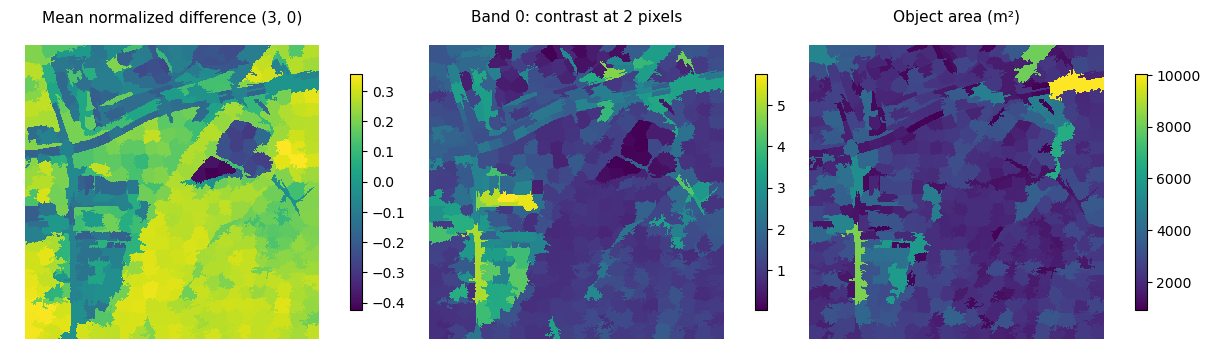

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), layout="constrained")
for ax, column, title in zip(
    axes,
    ["index_normalized_difference_b3_b0_mean", "b0_glcm_contrast_d2", "shape_area"],
    ["Mean normalized difference (3, 0)", "Band 0: contrast at 2 pixels", "Object area (m²)"],
):
    objects.plot(column=column, ax=ax, legend=True, cmap="viridis",
                 legend_kwds={"shrink": 0.65}, missing_kwds={"color": "lightgrey"})
    ax.set_title(title)
    ax.set_axis_off()
plt.show()

## Apply an analysis mask

File NoData masks are honored automatically. An additional boolean mask can
restrict measurements to an area of interest: `False` excludes a pixel. Here we
keep the central 768 × 768 pixels. Polygon boundaries and areas stay the same.

The separate `quality` table shows counts and fractions inside this area;
`objects` retains features from the whole crop. To use a quality mask from your
own data, apply it consistently to every spectral, index, and texture calculation.

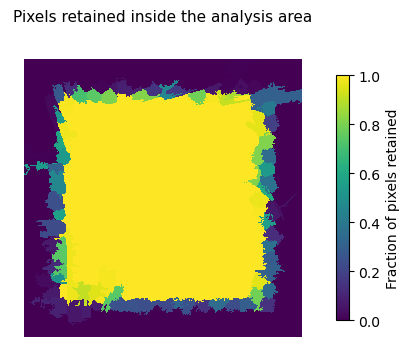

Objects affected by the mask: 232
Features with missing measurements: {}


In [6]:
rows, cols = np.indices(image.img_data.shape[:2])
valid_pixels = (rows >= 128) & (rows < 896) & (cols >= 128) & (cols < 896)
quality = extract_features(
    polygons, image, bands=[0], spectral=("valid_count", "valid_fraction"),
    percentiles=(), mask=valid_pixels,
)
fig, ax = plt.subplots(figsize=(5, 3.5), layout="constrained")
quality.plot(column="b0_valid_fraction", ax=ax, cmap="viridis", vmin=0, vmax=1,
             legend=True, legend_kwds={"label": "Fraction of pixels retained", "shrink": 0.8})
ax.set_title("Pixels retained inside the analysis area")
ax.set_axis_off()
plt.show()

missing = objects.drop(columns="geometry").isna().sum()
print(f"Objects affected by the mask: {(quality.b0_valid_fraction < 1).sum()}")
print("Features with missing measurements:", missing[missing > 0].to_dict())

## Save features and their settings

GeoPackage stores the geometry and feature columns. The extraction configuration
in `objects.attrs` is in-memory metadata, so we save it separately as JSON.

In [7]:
objects.to_file(output_dir / "object_features.gpkg", layer="objects", driver="GPKG")
(output_dir / "feature_settings.json").write_text(
    json.dumps(objects.attrs["obia_features"], indent=2), encoding="utf-8",
)
saved_objects = gpd.read_file(output_dir / "object_features.gpkg", layer="objects")
assert set(preview_columns).issubset(saved_objects.columns)
print(f"Saved {len(saved_objects)} objects and their feature settings to {output_dir}")

Saved 455 objects and their feature settings to example_outputs/02_raster_features


Try changing texture distances or entropy radii, then rerun feature extraction
without repeating segmentation. Adding every possible feature is not necessarily
helpful: keep measurements that have a useful relationship to your classes.

Continue with [object classification](https://obia.sefa.ai/examples/03_classification/). The
[raster feature guide](https://obia.sefa.ai/usage/raster-features/) lists definitions and units.